# Part II. Quantum states, Hamiltonians, and their optimization

In this exercise, we leverage PEPS to build & probe two dimensional quantum states.
Furthermore, we show how to optimize iPEPS targeting ground state of interacting Hamiltonian in the thermodynamic limit.

**Before you start**

Get the [standard tutorial dependencies](../README.md#installation).
Run cells from top to bottom. Four exercise groups concern the singlet,
projection, sublattice rotation, and double layers. All plotting, CTMRG,
density matrices, and transfer contractions are provided.
Replace each `raise NotImplementedError(...)` with your implementation, then rerun
that cell and its checks. The companion solution provides complete implementations.

## II.0 Prerequisite

Use the compact CTMRG routine below for a PEPS tensor `A[up,left,down,right,physical]`.
The routine assumes a real, $C_{4v}$-symmetric norm tensor.


In [1]:
# Provided: imports and numerical conventions.
import torch
torch.set_default_dtype(torch.float64)
torch.set_default_device("cpu")

def ctmrg(
    A: torch.Tensor,
    chi: int,
    ctm_max_iter=100,
    ctm_conv_tol=1.0e-8,
    callback=None,
    raise_on_nonconvergence=False,
):
    """Contract a PEPS norm with real C4v symmetry, retaining at most chi states.

    A has legs (up, left, down, right, physical). Returns C, T.
    callback(i, residual, finished, A, C, T) monitors each update.
    finished marks convergence or the final allowed iteration.
    Signed corner weights are retained; convergence compares their magnitudes.
    """
    assert A.ndim == 5, "A must be a 5-dimensional tensor."

    # Pair each ket/bra virtual leg to form the rank-four norm tensor.
    shape = tuple(d * d for d in A.shape[:4])
    E = torch.einsum("uldrp,ULDRp->uUlLdDrR", A, A.conj()).reshape(shape)

    # Trace the missing ket/bra pairs to initialize a free virtual boundary.
    C = torch.einsum("uldrp,ulDRp->dDrR", A, A.conj()).reshape(A.shape[2]**2, A.shape[3]**2)
    #
    #  --A--
    #   / \p   = 0--T--1   with usual index ordering for T [left,right,down]
    #    --A--      |
    #     /         2
    #
    T = torch.einsum("uldrp,uLDRp->lLrRdD", A, A.conj()).reshape(A.shape[1]**2, A.shape[3]**2, A.shape[2]**2)

    C = C / C.abs().max()
    T = T / T.abs().max()

    with torch.no_grad():
        spectrum = torch.linalg.eigvalsh(C).abs().sort(descending=True).values
        previous_spectrum = spectrum / spectrum.max()

    for i in range(ctm_max_iter):
        # ctm_iter
        # enlarge corner
        enlarged_C = torch.einsum("ab,bcd,eaf,dfgh->egch", C, T, T, E)
        left_chi, left_D, right_chi, right_D = enlarged_C.shape
        matrix = enlarged_C.reshape(left_chi * left_D, right_chi * right_D)
        # Remove roundoff asymmetry before diagonalizing.
        matrix = (matrix + matrix.mT) / 2
        # diagonalize and sort
        S, U = torch.linalg.eigh(matrix)
        indices = torch.argsort(S.abs(), descending=True)[:chi]
        S = S[indices]
        # get isometry
        U = U[:, indices].reshape(left_chi, left_D, len(indices))

        # absorb isometry into corner and edge tensors
        C = torch.diag(S)
        T = torch.einsum(T, (0, 1, 2), U, (1, 3, 4), E, (3, 2, 5, 6), U.conj(), (0, 5, 7), (7, 4, 6))

        # normalize corner and edge tensors and symmetrize
        C = C / C.abs().max()
        T = (T + T.permute(1, 0, 2)) / 2
        T = T / T.abs().max()

        # Compute the corner spectrum difference
        with torch.no_grad():
            spectrum = C.diagonal().abs().sort(descending=True).values
            # Boundary dimensions may grow during the first few updates.
            size = max(spectrum.numel(), previous_spectrum.numel())
            current_padded = torch.nn.functional.pad(
                spectrum, (0, size - spectrum.numel())
            )
            previous_padded = torch.nn.functional.pad(
                previous_spectrum, (0, size - previous_spectrum.numel())
            )
            residual = (current_padded - previous_padded).abs().sum()
            converged = bool(residual < ctm_conv_tol)
            previous_spectrum = spectrum

        if callback is not None:
            finished = converged or i == ctm_max_iter - 1
            callback(i, residual, finished, A, C, T)
        if converged:
            break

    if raise_on_nonconvergence and not converged:
        raise RuntimeError(
            f"CTMRG did not converge in {ctm_max_iter} iterations: "
            f"residual={residual.item():.3e}, tolerance={ctm_conv_tol:.3e}."
        )
    return C, T

## II.1 The spin-2 AKLT state — solution

AKLT state is an example of non-trivial gapped paramagnet in two dimensions. In addition to internal SU(2)-symmetry it also retains lattice symmetries and cannot be adiabatically connected to the atomic limit. 
It is constructed by a direct extension of Spin-1 AKLT construction to regular two-dimensional lattice.
Here, we consider a variant on square lattice. It admits a very simple (i)PEPS representation.

**Goals**

- Build a square-lattice spin S=2 AKLT state from virtual singlets and local linear maps.
- Work out a variation of AKLT S=2 iPEPS generated by $C_{4v}$-symmetric on-site tensor (and sublattice rotation).
- Find it's parent Hamiltonian and evaluate it, together with other observables one the ground state.

The Affleck–Kennedy–Lieb–Tasaki (**AKLT**) construction i) assigns four virtual
spin-$\tfrac12$ degrees of freedom (DoFs) to each square-lattice site, ii) entangles neighboring virtual spins in
singlets, and iii) maps each group of four virtual spins onto one physical spin $S=2$.
The PEPS bond dimension is $D=2$; its physical dimension is $d=2S+1=5$.


Reference: [Mambrini, Orús, and Poilblanc, *Systematic construction of spin liquids
on the square lattice from tensor networks with SU(2) symmetry*](https://arxiv.org/abs/1608.06003),
Sec. II A and Appendix B.2, for the staggered-frame convention and tensor coefficients.

### II.1.0 Pre-requisites: Spin irreps

In [2]:
from types import SimpleNamespace
from math import sqrt
import numpy as np
import matplotlib.pyplot as plt

torch.set_num_threads(2)


def close(actual, expected, atol=1e-12):
    expected = torch.as_tensor(expected, dtype=actual.dtype, device=actual.device)
    torch.testing.assert_close(actual, expected, atol=atol, rtol=0)

# Provided: spin irreps

# Spin-2 operators, with S^z in descending m order, and pi rotations.
m_values = torch.arange(2., -3., -1.)
Splus = torch.zeros((5, 5))
for s in range(1, 5):
    m = m_values[s]
    Splus[s - 1, s] = torch.sqrt(6 - m * (m + 1))
Sminus = Splus.T.contiguous()
irrepS2= SimpleNamespace(Sz= torch.diag(m_values), Sx= (Splus + Sminus) / 2, Sy= (Splus - Sminus).to(torch.complex128) / (2j), 
                         Splus=Splus, Sminus=Sminus)

# r = torch.tensor([[0., -1.], [1., 0.]])
# R = torch.fliplr(torch.diag(torch.tensor([1., -1., 1., -1., 1.])))
S12plus = torch.tensor([[0., 1.], [0., 0.]])
S12minus = S12plus.T.contiguous()
irrepShalf= SimpleNamespace(Sz= torch.diag(torch.tensor([1,-1]))/2.0, Sx= (S12plus + S12minus) / 2, Sy= (S12plus - S12minus).to(torch.complex128) / (2j), 
                            Splus=S12plus, Sminus=S12minus)

for name, op in irrepS2.__dict__.items():
    print(f"S2 {name}:\n{op}\n")
for name, op in irrepShalf.__dict__.items():
    print(f"Shalf {name}:\n{op}\n")

S2 Sz:
tensor([[ 2.,  0.,  0.,  0.,  0.],
        [ 0.,  1.,  0.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0.],
        [ 0.,  0.,  0., -1.,  0.],
        [ 0.,  0.,  0.,  0., -2.]])

S2 Sx:
tensor([[0.0000, 1.0000, 0.0000, 0.0000, 0.0000],
        [1.0000, 0.0000, 1.2247, 0.0000, 0.0000],
        [0.0000, 1.2247, 0.0000, 1.2247, 0.0000],
        [0.0000, 0.0000, 1.2247, 0.0000, 1.0000],
        [0.0000, 0.0000, 0.0000, 1.0000, 0.0000]])

S2 Sy:
tensor([[0.+0.0000j, 0.-1.0000j, 0.+0.0000j, 0.+0.0000j, 0.+0.0000j],
        [0.+1.0000j, 0.+0.0000j, 0.-1.2247j, 0.+0.0000j, 0.+0.0000j],
        [0.+0.0000j, 0.+1.2247j, 0.+0.0000j, 0.-1.2247j, 0.+0.0000j],
        [0.+0.0000j, 0.+0.0000j, 0.+1.2247j, 0.+0.0000j, 0.-1.0000j],
        [0.+0.0000j, 0.+0.0000j, 0.+0.0000j, 0.+1.0000j, 0.+0.0000j]])

S2 Splus:
tensor([[0.0000, 2.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 2.4495, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 2.4495, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.000

### II.1.1 Virtual state - product state of virtual singlets on each bond

We start with a square lattice, hosting 4 spin-1/2 DoFs (o) on each site

```text
  o     o        o         o 
 o o   o o  =>  o r -->-- l o   where r and l are entangled in a singlet
  o     o        o         o

  o     o        o         o
 o o   o o      o o       o o
  o     o        o         o
```

We want to pair the up in singlets to create $|\Omega\rangle = \prod_{b\in\mathrm{bonds}} |singlet\rangle_b$.

Using $|0\rangle=|\uparrow\rangle$ and $|1\rangle=|\downarrow\rangle$, we entangle two virtual spins r,l
in a singlet 

$$
|\omega\rangle=(|0_r\rangle,|1_r\rangle)\omega(|0_l\rangle,|1_l\rangle)^T = \frac{|0_r1_l\rangle-|1_r0_l\rangle}{\sqrt2},\qquad
\omega_{ab}=\frac1{\sqrt2}\begin{pmatrix}0&1\\-1&0\end{pmatrix}_{ab}.
$$

Crucially, the singlet has an orientation, from `r` to `l`, here choosen by -1 factor in front of term with $|0_l\rangle$.
A $-|\omega\rangle$ correspond to the opposite orientation.

**Exercise 1:** return the normalized coefficient matrix `omega[a,b]`.

In [3]:
import math 

def virtual_singlet():
    """Normalized singlet coefficients, with the even endpoint first."""
    return torch.tensor([[0., 1.], [-1., 0.]]) / math.sqrt(2)


omega = virtual_singlet()


### II.1.2 Map four virtual spins onto physical spin 2

At a site the four virtual spins span a $2^4=16$ dimensional space.
Its **fully symmetric** subspace has dimension five and carries spin 2.
Create a linear map $P$ 

$$
P: \otimes_4 \mathcal{H}_{S=1/2} \rightarrow \mathcal{H}_{S=2}
$$

which maps states from the product space of 4 spin-1/2s to its S=2 subspace.

Throughout, the leg order is **`(up,left,down,right,physical)`**:

```text
                     u(0), spin 1/2
                         |
  l(1), spin 1/2 -------[P]------- r(3), spin 1/2  =  P^s_uldr
                       / |
    s(4), spin 2 -----/  |
                         d(2), spin 1/2
```

The nonzero amplitudes for $s=0,1,2,3,4$ are $1,1/2,1/\sqrt6,1/2,1$.
They are not all one: normalization of the symmetric states matters.

**Exercise 2:** construct AKLT's on-site tensor $P$

In [4]:
# Function to lift a sum of four operators, each acting on individual spin-1/2 spaces to their product space
def op_to_space_of_4halfs(o1, o2, o3, o4)->torch.Tensor:
    assert o1.shape[0] == o2.shape[0] == o3.shape[0] == o4.shape[0]
    I= torch.eye(o1.shape[0])
    return torch.kron(torch.kron(torch.kron(o1, I), I), I) + torch.kron(torch.kron(torch.kron(I, o2), I), I) \
        + torch.kron(torch.kron(torch.kron(I, I), o3), I) + torch.kron(torch.kron(torch.kron(I, I), I), o4)

def P_aklt():
    """Projector on maximally symmetric subspace of 4 spin-1/2 DoFs"""
    # Initialize projection matrix P. The state with maximal spin is the first column
    P= torch.zeros(2**4,5) 
    P[0,0]= 1.0
    
    # TODO 2: Create remaining states by application of the lowering operator S^- = \sum_{x\in\{u,l,d,r\}} S^-_x
    P[:,1]= op_to_space_of_4halfs(irrepShalf.Sminus, irrepShalf.Sminus, irrepShalf.Sminus, irrepShalf.Sminus) @ P[:,0]
    P[:,2]= op_to_space_of_4halfs(irrepShalf.Sminus, irrepShalf.Sminus, irrepShalf.Sminus, irrepShalf.Sminus) @ P[:,1]
    P[:,3]= op_to_space_of_4halfs(irrepShalf.Sminus, irrepShalf.Sminus, irrepShalf.Sminus, irrepShalf.Sminus) @ P[:,2]
    P[:,4]= op_to_space_of_4halfs(irrepShalf.Sminus, irrepShalf.Sminus, irrepShalf.Sminus, irrepShalf.Sminus) @ P[:,3]

    # TODO 3: These state spannin S=2 irrep are not normalized. Normalize each one (column).
    for i in range(P.shape[1]):
        P[:,i] /= torch.norm(P[:,i])
    
    return P.reshape(2, 2, 2, 2, 5)

### II.1.3 Verify $C_{4v}$ symmetry

$C_{4v}$ is the symmetry group of a square: four rotations and four reflections.
The physical leg stays fixed while lattice operations permute `(u,l,d,r)`.
For example, a quarter turn sends `uldr` to `ldru`, and left/right reflection
sends it to `urdl`.

Our amplitudes depend only on the number of down spins, so they are invariant
under **all** permutations of the virtual legs, including $C_{4v}$.
This is the trivial, or $A_1$, representation. We verify it directly.

In [5]:
# Generate all eight virtual-leg permutations for later symmetry projections.
rotation = (1, 2, 3, 0)
mirror = (0, 3, 2, 1)
c4v = set()
perm = (0, 1, 2, 3)
for _ in range(4):
    c4v.add(perm)
    c4v.add(tuple(perm[i] for i in mirror))
    perm = tuple(perm[i] for i in rotation)

A= P_aklt()
for permutation in [(1, 2, 3, 0, 4), (3, 0, 1, 2, 4), (2, 1, 0, 3, 4), (0, 3, 2, 1, 4)]:
    torch.testing.assert_close(A, A.permute(permutation))
print("Square-lattice symmetries verified.")

Square-lattice symmetries verified.


## 3. From singlet bonds to a C4v PEPS

The AKLT state is obtained by applying $P$ on every site of the singlet network:

$$
|\Psi_{\rm AKLT}\rangle\propto
\left(\bigotimes_i P_i\right)
\left(\bigotimes_{\langle ij\rangle}|\omega\rangle_{ij}\right).
$$

```text
   Four virtual spins per site      Project onto spin 2

       o             o                 |s0>           |s1>
       |             |                   |              |
   o--( )--o ==ω== o--( )--o     ->     [P]----ω-------[P]
       |             |                   |              |
       o             o                  ...            ...

   ==ω== joins two virtual spin-1/2 objects into a singlet.
   Each ( ) groups four virtual spins; P maps them to one physical spin.
```

### 3.1. Absorb the singlets without losing C4v symmetry

An ordinary repeated-index contraction inserts the identity bond coefficients,
$|\Phi\rangle=|00\rangle+|11\rangle$, rather than a singlet. To keep a uniform
$C_{4v}$ tensor with ordinary bonds, use a **staggered spin frame**.

Let $r=e^{-i\pi\sigma^y/2}$ act on a virtual spin and
$R=e^{-i\pi S^y}$ act on a physical spin:

$$
r=\begin{pmatrix}0&-1\\1&0\end{pmatrix},\qquad
R_{s's}=(-1)^s\delta_{s',4-s}.
$$

The projection intertwines these rotations, $RP=P r^{\otimes4}$, and
$(I\otimes r)|\Phi\rangle=\sqrt2|\omega\rangle$.
Thus physical tensors $A$ on even sites and $B=RA$ on odd sites, joined by
ordinary bonds, reproduce the singlet construction up to an overall scalar.
Both tensors remain $C_{4v}$ symmetric.

```text
 Physical AKLT (ordinary bonds)       Uniform tensor in staggered frame

      A --- B --- A                         A --- A --- A
      |     |     |                         |     |     |
      B --- A --- B       <--- R on B ---    A --- A --- A
      |     |     |                         |     |     |
      A --- B --- A                         A --- A --- A

 A = P; B = R P.  Even/odd means (row+column) mod 2.
```

Contracting uniform $A$ therefore gives a state related to physical AKLT by $R$
on every odd site. This is a physical basis change; measurements must follow it.
For a finite open patch, the dangling odd-sublattice virtual boundary states
must be transformed consistently too.

**Exercise 3a:** contract $R$ onto the physical index to construct $B$.
**Exercise 3b:** absorb $r$ on all four virtual inputs and recover the same $B$.

In [6]:
# Provided: use the spin operators from the prerequisites in the staggered frame.
spins = {"x": irrepS2.Sx, "y": irrepS2.Sy, "z": irrepS2.Sz}
r = torch.tensor([[0., -1.], [1., 0.]])
R = torch.fliplr(torch.diag(torch.tensor([1., -1., 1., -1., 1.])))
close(torch.matrix_exp(-1j * torch.pi * spins["y"]), R)
close(R.T @ R, torch.eye(5))
close(r.T / sqrt(2), omega)
for axis, spin in spins.items():
    Rc = R.to(spin.dtype)
    close(Rc.T @ spin @ Rc, spin if axis == "y" else -spin)

In [7]:
def physical_rotation(A, R):
    """Apply a physical rotation, keeping legs (u,l,d,r,s)."""
    return torch.einsum("uldrt,st->uldrs", A, R)


def virtual_rotations(A, r):
    """Absorb r[local_virtual, bond_index] on each virtual input."""
    return torch.einsum("ijkls,iu,jv,kw,lx->uvwxs", A, r, r, r, r)

In [8]:
# Provided: verify the intertwiner and physical-bond construction.
B = physical_rotation(A, R)
close(B, virtual_rotations(A, r))
for perm in c4v:
    close(B, B.permute(*perm, 4))
# Acting on the second endpoint of an identity bond gives r.T, a singlet matrix.
close(torch.eye(2) @ r.T, sqrt(2) * omega)
print("R P = P r⊗4; both sublattice tensors preserve C4v symmetry.")

R P = P r⊗4; both sublattice tensors preserve C4v symmetry.


### 3.2. An exact local parent-Hamiltonian check

Two neighboring physical spins each have $S=2$, so their total spin can be
$J=0,1,2,3,4$. Their shared virtual singlet contributes zero spin, leaving
six virtual spin-$\tfrac12$ objects. These can have at most $J=3$.
Consequently the AKLT pair has **no $J=4$ component**.

The positive parent Hamiltonian is

$$
H=\sum_{\langle ij\rangle}P_{J=4}^{ij}.
$$

Write $X=\mathbf S_i\cdot\mathbf S_j$.
Its eigenvalues are $[J(J+1)-12]/2=-6,-5,-3,0,4$.
The polynomial which is one at $X=4$ and zero at the other four values is

$$
P_{J=4}=\frac{X(X+3I)(X+5I)(X+6I)}{2520}.
$$

The following provided check keeps all six external virtual spins open.
It is an exact local tensor identity and needs no infinite environment.

In [9]:
# Provided: parent projector in the physical, unrotated spin basis.
I25 = torch.eye(25)
spin_dot = sum(torch.kron(op.contiguous(), op.contiguous())
               for op in spins.values()).real
P4 = spin_dot @ (spin_dot + 3 * I25) @ (spin_dot + 5 * I25) @ (spin_dot + 6 * I25) / 2520
close(P4, P4.T)
close(P4 @ P4, P4)
close(torch.trace(P4), 9.)  # J=4 has 2J+1 states.

# Left tensor legs: (i,j,k,x,s); right tensor: (a,y,b,c,t).
# x--omega--y is their shared bond; i,j,k,a,b,c remain open.
pair = torch.einsum("ijkxs,xy,aybct->ijkabcst", A, omega, A)
pair_map = pair.reshape(64, 25).T
close(P4 @ pair_map, torch.zeros_like(pair_map))
print("The local AKLT pair is annihilated by P(J=4).")

The local AKLT pair is annihilated by P(J=4).


## 4. Construct the double layers

To contract a norm or expectation value, combine ket and bra tensors.
For a local operator $O$ with $O_{ts}=\langle t|O|s\rangle$, define

$$
(E_O)_{(uU)(lL)(dD)(rR)}
=\sum_{s,t}A_{uldrs}\,\overline{A_{ULDRt}}\,O_{ts}.
$$

Capital virtual indices belong to the bra. Pair each ket/bra index **before**
reshaping: `(u,U,l,L,d,D,r,R)` becomes four indices of dimension $D^2=4$.
The norm layer $E=E_I$ is real and $C_{4v}$ symmetric.
In contrast, $E_{S^y}$ is imaginary, so preserve complex arithmetic for operators.

Since $B=RA$ and $R^\dagger R=I$, $A$ and $B$ have the same norm layer.
We can therefore use a single $E$, a single corner $C$, and a single edge $T$
in the symmetry-reduced CTMRG contraction.

**Exercise 4a:** contract ket, bra, and $O$ with the matrix elements in the order above.
**Exercise 4b:** fuse the adjacent ket/bra pairs. `O=None` selects the norm.

In [10]:
def double_layer(A, O=None):
    """E_O with four fused ket/bra legs. Operator entries are O[t,s]."""
    if O is None:
        O = torch.eye(A.shape[-1], dtype=A.dtype, device=A.device)
    dtype = torch.promote_types(A.dtype, O.dtype)
    ket, op = A.to(dtype), O.to(dtype)
    layer = torch.einsum("uldrs,ULDRt,ts->uUlLdDrR", ket, ket.conj(), op)
    D = A.shape[0]
    return layer.reshape(D * D, D * D, D * D, D * D)

In [11]:
# Provided: fusion, norm symmetry, sublattice equivalence, and complex-order checks.
E = double_layer(A)
assert E.shape == (4, 4, 4, 4) and not E.is_complex()
close(E, double_layer(B))
for perm in c4v:
    close(E, E.permute(perm))
E_y = double_layer(A, spins["y"])
assert E_y.is_complex()
# Ket 0000 has s=0; bra 0001 has t=1; Sy[1,0]=+i and A[0001,1]=1/2.
# This catches an accidental O[s,t] transpose, which Sy-Sy correlations alone miss.
close(E_y[0, 0, 0, 1], 0.5j)
print("Norm layer: D_eff=4, C4v symmetric; complex operator ordering verified.")

Norm layer: D_eff=4, C4v symmetric; complex operator ordering verified.


## 5. Contract the infinite norm with supplied CTMRG

The Ising tutorial's corner-transfer matrix renormalization group (**CTMRG**)
applies to our real rank-four norm tensor as well. It approximates the infinite
environment by corner matrices $C$ and edge tensors $T$ with boundary dimension
at most $\chi$:

```text
     C--T--C                  C[a,b]       T[a,b,u]
     |  |  |                     a--C        a--T--b
     T--E--T                        |           |
     |  |  |                        b           u
     C--T--C
```

Each iteration enlarges a corner, keeps the eigenvectors with largest absolute
eigenvalues, and absorbs a layer into the edge. Signed eigenvalues are retained
in $C$; convergence compares their sorted absolute values. Overall scales of
$C$ and $T$ cancel from normalized measurements.

Use `ctmrg` from the prerequisites, passing the rank-five PEPS tensor `A`.
It builds `E` internally and closes missing virtual ket/bra pairs with the identity,
giving a deterministic free virtual boundary. It returns `C, T`; the callback
reports the iteration count and residual.
Convergence of the corner spectrum controls iteration error; comparing several
$\chi$ values probes truncation error. A dense cutoff can split spin multiplets,
so check isotropy rather than assuming exact symmetry at finite $\chi$.

In [12]:
# Provided: convergence monitor and default infinite environment.
def report_ctm(i, residual, finished, A, C, T):
    if finished:
        print(f"iterations={i + 1}; corner residual={residual.item():.2e}")


C, T = ctmrg(A, chi=24, ctm_max_iter=500, ctm_conv_tol=1e-8,
             callback=report_ctm, raise_on_nonconvergence=True)
print("chi=24; C:", tuple(C.shape), "; T:", tuple(T.shape))


iterations=20; corner residual=4.96e-09
chi=24; C: (24, 24) ; T: (24, 24, 4)


## 6. Measure local physical spins and parent energy

Keep physical ket and bra indices open to obtain the one-site and two-site
reduced density matrices (RDMs). Their normalization is their trace.
We store $\rho_1[s,t]$ and $\rho_2[s_1,s_2,t_1,t_2]$, with all ket indices first.

```text
    C--T--C             C--T---T--C
    |  |  |             |  |   |  |
    T--AĀ--T            T--AĀ--AĀ--T
    |  |  |             |  |   |  |
    C--T--C             C--T---T--C

AĀ has physical s,t open. Each internal virtual line is a fused ket/bra pair.
```

These contractions use uniform $A$, hence return RDMs in the staggered frame.
For a pair whose first site is even, convert to the physical basis as
$\rho_2^{\rm phys}=(I\otimes R)\rho_2^{\rm frame}(I\otimes R)^\dagger$.
Equivalently transform the operator by $O\mapsto(I\otimes R)^\dagger O(I\otimes R)$.

The spin-singlet state has $\rho_1=I_5/5$, zero magnetization, and
$\langle(S^\alpha)^2\rangle=S(S+1)/3=2$ for each axis.
Its parent-projector expectation is zero. The square lattice has two bonds
per site, so the parent energy per site is $2\langle P_{J=4}\rangle$.

In [13]:
def physical_open_layer(A):
    """A_s A*_t; fuse each adjacent ket/bra virtual pair, leave (s,t) open."""
    D, p = A.shape[0], A.shape[-1]
    return torch.einsum('uldrs,ULDRt->uUlLdDrRst', A, A.conj()).reshape(
        D * D, D * D, D * D, D * D, p, p)


def one_site_environment(C, T):
    """Four corners and four edges, with open (u,l,d,r) fused legs."""
    half = torch.einsum('ab,bcu->acu', C, T)
    half = torch.einsum('acu,cdv->aduv', half, half)
    return torch.einsum('abuv,badc->ucdv', half, half)


def rdm_1site(A, C, T):
    """Normalized rho[s,t] in the uniform tensor's staggered spin frame."""
    environment = one_site_environment(C, T)
    layer = physical_open_layer(A)
    dtype = torch.promote_types(environment.dtype, layer.dtype)
    rho = torch.einsum('uldr,uldrst->st', environment.to(dtype), layer.to(dtype))
    return rho / rho.trace()


def strip_boundary(C, T):
    """Cap of a horizontal strip: top endpoint, bottom endpoint, open bond."""
    return torch.einsum('ai,ijl,jb->abl', C, T, C)


def strip_step(state, layer, T):
    """Propagate a b x b x D boundary without building a dense transfer matrix."""
    dtype = torch.promote_types(torch.promote_types(state.dtype, layer.dtype), T.dtype)
    state, layer, edge = state.to(dtype), layer.to(dtype), T.to(dtype)
    top = torch.einsum('abl,acu->blcu', state, edge)
    middle = torch.einsum('blcu,ulvr->bcvr', top, layer)
    return torch.einsum('bcvr,bdv->cdr', middle, edge)


def strip_contraction(layers, C, T):
    """Contract any finite list of site layers between the CTM strip caps."""
    cap = strip_boundary(C, T)
    state = cap
    for layer in layers:
        state = strip_step(state, layer, T)
    return torch.einsum('abl,abl->', state, cap.to(state.dtype))


def rdm_2site(A, C, T):
    """Nearest neighbors: rho[s1,s2,t1,t2] in the uniform/staggered frame.

    Construct the two open half strips independently, so no intermediate
    contains both physical-site pairs and two boundary indices.
    """
    cap, layer = strip_boundary(C, T), physical_open_layer(A)
    dtype = torch.promote_types(cap.dtype, layer.dtype)
    cap, layer, edge = cap.to(dtype), layer.to(dtype), T.to(dtype)
    top = torch.einsum('abl,acu->blcu', cap, edge)
    middle = torch.einsum('blcu,ulvrst->bcvrst', top, layer)
    half = torch.einsum('bcvrst,bdv->cdrst', middle, edge)
    rho = torch.einsum('ablst,abluv->sutv', half, half)
    return rho / torch.einsum('abab->', rho)


def expectation(rho, operator):
    """Trace(rho O), also for a multi-site rho reshaped to a square matrix."""
    p = operator.shape[0]
    dtype = torch.promote_types(rho.dtype, operator.dtype)
    return torch.einsum('st,ts->', rho.reshape(p, p).to(dtype), operator.to(dtype))

In [14]:
# Provided: RDM checks and physical measurements.
rho1 = rdm_1site(A, C, T)
rho2_frame = rdm_2site(A, C, T).reshape(25, 25)
U_pair = torch.kron(torch.eye(5), R)
rho2 = U_pair @ rho2_frame @ U_pair.T


def real_expectation(rho, operator):
    value = expectation(rho, operator)
    if value.is_complex():
        assert abs(float(value.imag)) < 1e-10
        value = value.real
    return float(value)


close(torch.trace(rho1), 1.)
close(torch.trace(rho2), 1.)
close(rho1, rho1.T.conj())
close(rho2, rho2.T.conj())
assert float(torch.linalg.eigvalsh(rho1).min()) > -1e-10
assert float(torch.linalg.eigvalsh(rho2).min()) > -1e-10
close(rho1, torch.eye(5) / 5, atol=1e-4)
magnetizations = {axis: real_expectation(rho1, op) for axis, op in spins.items()}
moments = {axis: real_expectation(rho1, op @ op) for axis, op in spins.items()}
nearest = {axis: real_expectation(rho2, torch.kron(op.contiguous(), op.contiguous()))
           for axis, op in spins.items()}
parent_bond_energy = real_expectation(rho2, P4)
for axis in spins:
    assert abs(magnetizations[axis]) < 1e-4
    assert abs(moments[axis] - 2) < 1e-4
assert max(nearest.values()) - min(nearest.values()) < 1e-4
assert abs(parent_bond_energy) < 1e-10
assert abs(sum(nearest.values()) - (-3.55855)) < 1e-4
print("axis       <S>            <S²>           <S0 S1> (physical)")
for axis in spins:
    print(f" {axis}    {magnetizations[axis]: .8f}      {moments[axis]: .8f}      {nearest[axis]: .8f}")
print(f"<S0 · S1> = {sum(nearest.values()):.10f}")
print(f"<P(J=4)> per bond = {parent_bond_energy:.3e}")
print(f"Parent energy per site = {2 * parent_bond_energy:.3e}")

axis       <S>            <S²>           <S0 S1> (physical)
 x    -0.00000000       2.00000000      -1.18618469
 y     0.00000000       2.00000000      -1.18618469
 z    -0.00000000       2.00000000      -1.18618469
<S0 · S1> = -3.5585540718
<P(J=4)> per bond = -1.884e-16
Parent energy per site = -3.769e-16


## 7. Correlations at physical separation $r$

Compute the connected correlations along one row,

$$
C_{\alpha\alpha}(r)=\langle S_0^\alpha S_r^\alpha\rangle
-\langle S_0^\alpha\rangle\langle S_r^\alpha\rangle,
\qquad C_{\mathbf S\cdot\mathbf S}(r)=\sum_{\alpha=x,y,z}C_{\alpha\alpha}(r).
$$

Here $r=0$ means the **same site**, so use $E_{(S^\alpha)^2}$; nearest
neighbors have $r=1$. For $r\geq1$, insert $E_{S^\alpha}$ at the endpoints
and $E$ at the $r-1$ sites between them:

```text
    C---T-------T---- ... ----T---C
    |   |       |            |   |
    T--E_S------E--- ... ---E_S--T
    |   |       |            |   |
    C---T-------T---- ... ----T---C
        0       1            r
```

Normalize by a strip of the **same length** with only norm layers.
Propagate a boundary with three open indices rather than forming a large
dense transfer matrix. The supplied code rescales numerator and denominator
together during propagation and supports complex $S^y$ insertions.

In the staggered frame $R^\dagger(S^x,S^y,S^z)R=(-S^x,S^y,-S^z)$.
Restore physical correlations with $(-1)^r$ for $xx$ and $zz$, and no extra
sign for $yy$. Subtract the means in the same physical frame.

In [15]:
def strip_correlations(A, C, T, operators, max_distance=12):
    """Physical connected xx, yy, zz and dot correlations at r=0,...,rmax.

    operators maps 'x','y','z' to spin-2 matrices. double_layer(A,O), defined
    in the construction exercise, uses O[t,s]. The uniform A is a staggered
    frame: rotate the second physical observable by R for odd separations.
    """
    E = double_layer(A)
    cap = strip_boundary(C, T)
    rho = rdm_1site(A, C, T)
    result = {}
    for axis, operator in operators.items():
        magnetization = expectation(rho, operator)
        same_site = (strip_contraction([double_layer(A, operator @ operator)], C, T)
                     / strip_contraction([E], C, T) - magnetization**2)
        values = [same_site.real.item()]
        insertion = double_layer(A, operator)
        state = strip_step(cap, insertion, T)
        norm_state = strip_step(cap, E, T)
        for distance in range(1, max_distance + 1):
            numerator_state = strip_step(state, insertion, T)
            norm_state = strip_step(norm_state, E, T)
            numerator = torch.einsum('abl,abl->', numerator_state,
                                     cap.to(numerator_state.dtype))
            denominator = torch.einsum('abl,abl->', norm_state, cap)
            parity = (-1) ** distance if axis in ('x', 'z') else 1
            value = parity * (numerator / denominator - magnetization**2)
            assert value.imag.abs() < 1e-10 if value.is_complex() else True
            values.append(value.real.item())
            state = strip_step(state, E, T)
            # A common rescaling prevents overflow without changing ratios.
            scale = norm_state.abs().max()
            norm_state, state = norm_state / scale, state / scale
        result[axis] = torch.tensor(values, dtype=torch.float64)
    result['dot'] = sum(result[axis] for axis in ('x', 'y', 'z'))
    return result

In [16]:
# Provided: cross-check independently contracted strips against the RDMs.
correlations = strip_correlations(A, C, T, spins, max_distance=12)
identity_layer = double_layer(A, torch.eye(5))
for length in (1, 2, 5):
    close(strip_contraction([identity_layer] * length, C, T)
          / strip_contraction([E] * length, C, T), 1.)
for axis in spins:
    close(correlations[axis][0], moments[axis] - magnetizations[axis]**2)
    odd_mean = magnetizations[axis] if axis == "y" else -magnetizations[axis]
    close(correlations[axis][1], nearest[axis] - magnetizations[axis] * odd_mean)
close(correlations["dot"][0], 6., atol=1e-4)
print("Physical r       Cxx              Cyy              Czz              Cdot")
for distance in range(13):
    print(f"   {distance:2d}      " + "   ".join(
        f"{float(correlations[axis][distance]): .9f}" for axis in ("x", "y", "z", "dot")))

Physical r       Cxx              Cyy              Czz              Cdot
    0       2.000000000    2.000000000    2.000000000    6.000000000
    1      -1.186184691   -1.186184691   -1.186184691   -3.558554072
    2       0.551278678    0.551278678    0.551278678    1.653836035
    3      -0.280950730   -0.280950730   -0.280950730   -0.842852189
    4       0.150851657    0.150851657    0.150851657    0.452554970
    5      -0.083526978   -0.083526978   -0.083526978   -0.250580935
    6       0.047161294    0.047161294    0.047161294    0.141483882
    7      -0.026986303   -0.026986303   -0.026986303   -0.080958908
    8       0.015591934    0.015591934    0.015591934    0.046775803
    9      -0.009074416   -0.009074416   -0.009074416   -0.027223247
   10       0.005311010    0.005311010    0.005311010    0.015933029
   11      -0.003122080   -0.003122080   -0.003122080   -0.009366241
   12       0.001841682    0.001841682    0.001841682    0.005525046


### 7.1. Compare boundary dimensions and plot the decay

A corner spectrum can converge while the environment still has finite-$\chi$
error. Repeat the same measurement at $\chi=16,24,48$ and inspect their
agreement. The absolute-correlation plot removes the alternating sign only
for visualization; the signed plot retains the physical antiferromagnetic
correlations. The approximate numerical values are determined by the
contraction, not built into the state construction.

chi=16
iterations=18; corner residual=6.05e-09


chi=48


iterations=21; corner residual=8.19e-09


chi       Cdot(1)       max component splitting


 16     -3.55855356       1.55e-15
 24     -3.55855407       2.44e-15
 48     -3.55855409       2.66e-15
Largest chi=24/48 correlation difference for r=0..12: 1.67e-05


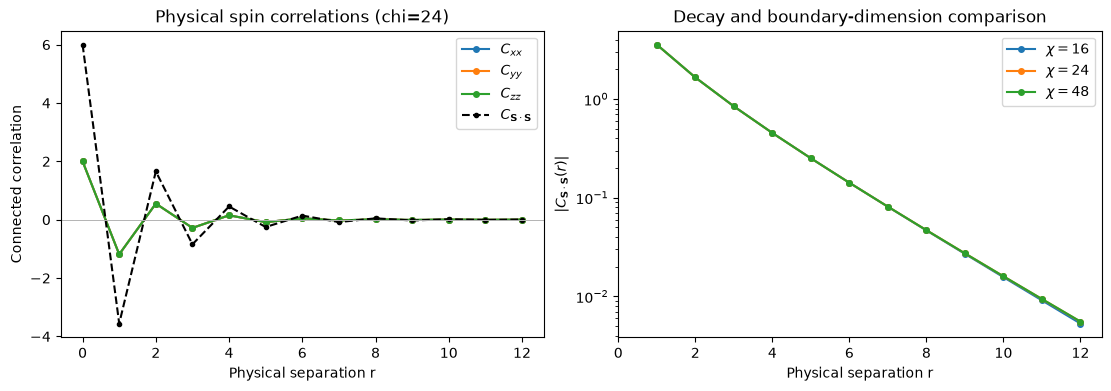

In [17]:
# Provided: chi comparison, reusing the default chi=24 result.
scans = {24: correlations}
environments = {24: (C, T)}
for chi in (16, 48):
    print(f"chi={chi}")
    C_chi, T_chi = ctmrg(A, chi=chi, ctm_max_iter=500, ctm_conv_tol=1e-8,
                       callback=report_ctm, raise_on_nonconvergence=True)
    scans[chi] = strip_correlations(A, C_chi, T_chi, spins, max_distance=12)
    environments[chi] = (C_chi, T_chi)
print("chi       Cdot(1)       max component splitting")
for chi in (16, 24, 48):
    components = torch.stack([scans[chi][axis] for axis in spins])
    splitting = float((components.max(dim=0).values - components.min(dim=0).values).max())
    print(f"{chi:3d}     {float(scans[chi]['dot'][1]): .8f}       {splitting:.2e}")
difference = max(float((scans[24][axis] - scans[48][axis]).abs().max())
                 for axis in ("x", "y", "z", "dot"))
print(f"Largest chi=24/48 correlation difference for r=0..12: {difference:.2e}")
assert difference < 1e-4

distances = np.arange(13)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for axis in ("x", "y", "z"):
    axes[0].plot(distances, correlations[axis].numpy(), "o-", ms=4,
                 label=rf"$C_{{{axis}{axis}}}$")
axes[0].plot(distances, correlations["dot"].numpy(), "k.--", label=r"$C_{\mathbf{S}\cdot\mathbf{S}}$")
axes[0].axhline(0, color="0.7", lw=.7)
axes[0].set(xlabel="Physical separation r", ylabel="Connected correlation",
            title="Physical spin correlations (chi=24)", xticks=distances[::2])
axes[0].legend()
for chi in (16, 24, 48):
    axes[1].semilogy(distances[1:], scans[chi]["dot"][1:].abs().numpy(),
                     "o-", ms=4, label=rf"$\chi={chi}$")
axes[1].set(xlabel="Physical separation r", ylabel=r"$|C_{\mathbf{S}\cdot\mathbf{S}}(r)|$",
            title="Decay and boundary-dimension comparison", xticks=distances[::2])
axes[1].legend()
fig.canvas.draw()
plt.show()

**Discussion**

- Which ingredient sets the physical dimension to five, and which sets the bond dimension to two?
- Why do the binomial normalization factors preserve all square-lattice symmetries?
- Why can the norm use one tensor even though physical observables need a sublattice convention?
- Which check establishes the parent-Hamiltonian property independently of CTMRG?
- How does the $\chi$ comparison distinguish truncation error from iteration convergence?

## 8. Variational iPEPS optimization

Here we use the spin-2 Heisenberg model as an example to demonstrate the workflow of variational iPEPS optimizations. The Hamiltonian is written as

  $$
  H=\sum_{\langle ij\rangle}\mathbf S_i\cdot\mathbf S_j,
  $$
where set the coupling to $J=1$.

### 8.1. Initialize one variational tensor

- Use the checkerboard pattern from section 3, with **only $A$ varied**:
  $$
  B_{uldrs}=\sum_t R_{st}A_{uldrt},\qquad R=e^{-i\pi S^y}.
  $$
- Since $R^\dagger R=I$, both sublattices have the same norm layer. One set of CTM environment tensors suffices.

In [18]:
torch.manual_seed(7)
D_opt, chi_opt = 2, 16

def symmetric_tensor(A):
    """Symmetrize A by applying the all the transformations in c4v."""
    site = sum(A.permute(*perm, 4) for perm in sorted(c4v)) / len(c4v)
    return site / site.norm()


data = torch.randn(D_opt, D_opt, D_opt, D_opt, 5)
A = symmetric_tensor(data).requires_grad_()


### 8.2. Define the energy

- `rdm_2site(A, C, T)` returns the normalized two-site RDM in the uniform, staggered frame.
- Rotate the bond Hamiltonian into this frame:

  $$
  h_{\mathrm{frame}}=(I\otimes R)^\dagger
  (\mathbf S_i\cdot\mathbf S_j)(I\otimes R)
  =-S^x\otimes S^x+S^y\otimes S^y-S^z\otimes S^z.
  $$

- All nearest-neighbor bonds have the same energy in this ansatz. There are two bonds per square-lattice site:

  $$
  e=2\,\mathrm{Tr}(\rho_{ij}^{\mathrm{frame}}h_{\mathrm{frame}}).
  $$

- Keep every contraction in PyTorch so the energy remains differentiable through both the RDM and CTMRG.


In [19]:
U_pair = torch.kron(torch.eye(5), R)
h_frame = U_pair.mH @ spin_dot @ U_pair

def energy_per_site(A, C, T):
    """Contract the two-site RDM with the bond Hamiltonian; count two bonds per site."""
    rho = rdm_2site(A, C, T).reshape(25, 25)
    return 2 * torch.einsum("st,ts->", rho, h_frame)


### 8.3. Optimize with L-BFGS

- Give [L-BFGS](https://docs.pytorch.org/docs/stable/generated/torch.optim.LBFGS.html) the single parameter `A`.
- Each closure symmetrizes the tensor, converges a fresh environment with the CTMRG from the beginning, and evaluates the energy.


In [20]:
optimizer = torch.optim.LBFGS(
    [A], max_iter=1, max_eval=25, line_search_fn="strong_wolfe"
)
ctm_options = dict(chi=chi_opt, ctm_max_iter=300, ctm_conv_tol=1e-8,
                   raise_on_nonconvergence=False)


def closure():
    """Return the current energy and populate A.grad."""
    optimizer.zero_grad()

    # symmetrize A
    site = symmetric_tensor(A)
    C_opt, T_opt = ctmrg(site, **ctm_options)
    energy = energy_per_site(site, C_opt, T_opt)

    # Backpropagation
    energy.backward()
    return energy


energies = []
for step in range(30):
    energy = optimizer.step(closure)  # Energy before this update.
    energies.append(energy.item())
    print(f"Step {step + 1:2d}: starting energy = {energy.item():.8f}")


Step  1: starting energy = -4.60772029
Step  2: starting energy = -6.54394767


Step  3: starting energy = -7.95428409
Step  4: starting energy = -8.02935750


Step  5: starting energy = -8.05535461
Step  6: starting energy = -8.16295192
Step  7: starting energy = -8.22462055


Step  8: starting energy = -8.30959352
Step  9: starting energy = -8.38468063


Step 10: starting energy = -8.40880799


...

Step 21: starting energy = -8.51401496
Step 22: starting energy = -8.51437909


Step 23: starting energy = -8.51475158
Step 24: starting energy = -8.51498550


Step 25: starting energy = -8.51523713
Step 26: starting energy = -8.51533930


Step 27: starting energy = -8.51537574
Step 28: starting energy = -8.51538835


Step 29: starting energy = -8.51539989
Step 30: starting energy = -8.51541711


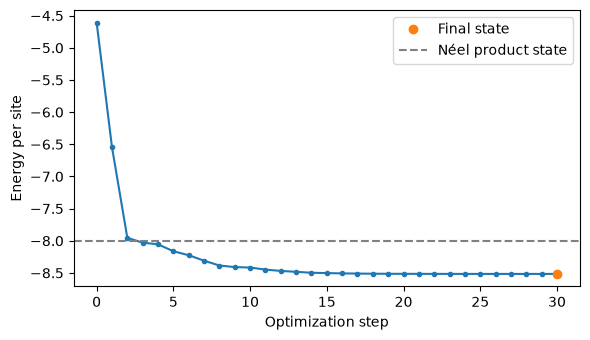

In [21]:
with torch.no_grad():
    A_opt = symmetric_tensor(A)
    B_opt = physical_rotation(A_opt, R)
    C_opt, T_opt = ctmrg(A_opt, **ctm_options)
    final_energy = energy_per_site(A_opt, C_opt, T_opt).item()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(len(energies) + 1), energies + [final_energy], "o-", ms=3)
ax.plot(len(energies), final_energy, "o", label="Final state")
ax.axhline(-8, color="gray", ls="--", label="Néel product state")
ax.set(xlabel="Optimization step", ylabel="Energy per site")
ax.legend()
fig.tight_layout()
plt.show()


The same workflow can be used to explore the interpolation between the Heisenberg and AKLT Hamiltonians:

$$
H(g)=(1-g)H_{\mathrm{Heisenberg}}+gH_{\mathrm{AKLT}}.
$$

An intesting question is to locate the quantum phase transition and investigate its nature.
